# 03 · Feature engineering
**Owner:** Dhanvin Vadlamudi

Two kinds of features:
* **TF-IDF** on the premise and hypothesis text
* **Structured** features from the parsed facts and the PC graph (notebook 02)

TF-IDF and the scaler are fitted on train only. Test is not used here.

In [1]:
# ─── IMPORTS ─────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score

In [2]:
# ─── LOAD DATA ─────
data = pd.read_csv("../data/processed/parsed.csv")
graphs = pd.read_csv("../data/processed/premise_graphs.csv").fillna("")

data = data.merge(graphs[["premise_id", "directed_edges", "undirected_edges", "mec_size"]], on="premise_id")
data.head()

,premise_id,split,premise,hypothesis,label,num_variables,template,x,y,relation,variables,mec_support,directed_edges,undirected_edges,mec_size
0,18,train,Suppose there is a closed system of 5 variable...,E directly causes B.,0,5,child,E,B,direct_cause,"A, B, C, D, E",0.0,A->E;B->E;C->E;D->E,A-B;A-C;A-D,4
1,25,train,Suppose there is a closed system of 5 variable...,"E is a cause for D, but not a direct one.",0,5,non-child descendant,E,D,indirect_cause,"A, B, C, D, E",0.0,A->C;A->D;B->C;B->D;C->E,C-D,2
2,25,train,Suppose there is a closed system of 5 variable...,E directly causes D.,0,5,child,E,D,direct_cause,"A, B, C, D, E",0.0,A->C;A->D;B->C;B->D;C->E,C-D,2
3,25,train,Suppose there is a closed system of 5 variable...,D causes something else which causes E.,0,5,non-parent ancestor,D,E,indirect_cause,"A, B, C, D, E",0.5,A->C;A->D;B->C;B->D;C->E,C-D,2
4,25,train,Suppose there is a closed system of 5 variable...,D directly causes E.,0,5,parent,D,E,direct_cause,"A, B, C, D, E",0.0,A->C;A->D;B->C;B->D;C->E,C-D,2


In [3]:
# ─── STEP 1: CLAIM TYPE ─────
# one-hot encode the relation
data = pd.concat([data, pd.get_dummies(data["relation"], prefix="rel", dtype=int)], axis=1)
data[["relation", "rel_collider", "rel_confounder", "rel_direct_cause", "rel_indirect_cause"]].head()

,relation,rel_collider,rel_confounder,rel_direct_cause,rel_indirect_cause
0,direct_cause,0,0,1,0
1,indirect_cause,0,0,0,1
2,direct_cause,0,0,1,0
3,indirect_cause,0,0,0,1
4,direct_cause,0,0,1,0


In [4]:
# ─── STEP 2: WHAT THE PREMISE SAYS ─────
data["n_correlations"] = data["premise"].str.count("correlates with")
data["n_independencies"] = data["premise"].str.count("independent")

# what the premise says about the two variables X and Y of the hypothesis
data["xy_correlated"] = data.apply(lambda r: f"{r.x} correlates with {r.y}." in r.premise or f"{r.y} correlates with {r.x}." in r.premise, axis=1).astype(int)
data["xy_independent"] = data.apply(lambda r: f"{r.x} is independent of {r.y}." in r.premise or f"{r.y} is independent of {r.x}." in r.premise, axis=1).astype(int)
data["xy_independent_given"] = data.apply(lambda r: f"{r.x} and {r.y} are independent given" in r.premise or f"{r.y} and {r.x} are independent given" in r.premise, axis=1).astype(int)

data[["hypothesis", "xy_correlated", "xy_independent", "xy_independent_given"]].head()

,hypothesis,xy_correlated,xy_independent,xy_independent_given
0,E directly causes B.,1,0,0
1,"E is a cause for D, but not a direct one.",1,0,1
2,E directly causes D.,1,0,1
3,D causes something else which causes E.,1,0,1
4,D directly causes E.,1,0,1


In [5]:
# ─── STEP 3: WHAT THE PC GRAPH SAYS ─────
data["edge_x_to_y"] = data.apply(lambda r: f"{r.x}->{r.y}" in r.directed_edges, axis=1).astype(int)
data["edge_y_to_x"] = data.apply(lambda r: f"{r.y}->{r.x}" in r.directed_edges, axis=1).astype(int)
data["edge_undirected"] = data.apply(lambda r: f"{min(r.x, r.y)}-{max(r.x, r.y)}" in r.undirected_edges, axis=1).astype(int)
data["log_mec_size"] = np.log(data["mec_size"])

data[["hypothesis", "directed_edges", "edge_x_to_y", "edge_y_to_x", "edge_undirected", "mec_support"]].head()

,hypothesis,directed_edges,edge_x_to_y,edge_y_to_x,edge_undirected,mec_support
0,E directly causes B.,A->E;B->E;C->E;D->E,0,1,0,0.0
1,"E is a cause for D, but not a direct one.",A->C;A->D;B->C;B->D;C->E,0,0,0,0.0
2,E directly causes D.,A->C;A->D;B->C;B->D;C->E,0,0,0,0.0
3,D causes something else which causes E.,A->C;A->D;B->C;B->D;C->E,0,0,0,0.5
4,D directly causes E.,A->C;A->D;B->C;B->D;C->E,0,0,0,0.0


In [6]:
FEATURES = ["num_variables", "n_correlations", "n_independencies",
            "rel_collider", "rel_confounder", "rel_direct_cause", "rel_indirect_cause",
            "xy_correlated", "xy_independent", "xy_independent_given",
            "edge_x_to_y", "edge_y_to_x", "edge_undirected", "log_mec_size", "mec_support"]

train = data[data["split"] == "train"]
validation = data[data["split"] == "validation"]
y_train = train["label"]
y_val = validation["label"]

train[FEATURES].describe().T[["mean", "min", "max"]].round(2)

,mean,min,max
num_variables,5.96,5.0,6.00
n_correlations,12.84,0.0,15.00
n_independencies,37.56,2.0,240.00
rel_collider,0.17,0.0,1.00
rel_confounder,0.17,0.0,1.00
rel_direct_cause,0.33,0.0,1.00
rel_indirect_cause,0.33,0.0,1.00
xy_correlated,0.87,0.0,1.00
xy_independent,0.13,0.0,1.00
xy_independent_given,0.42,0.0,1.00


In [7]:
train[FEATURES].isnull().sum().sum()

np.int64(0)

No missing values, so no imputation. The columns are on different scales, so we standardise them.

In [8]:
# ─── STEP 4: TF-IDF (fit on train, transform validation) ─────
# token_pattern keeps one-letter words, because A, B, C are the variable names
tfidf_premise = TfidfVectorizer(token_pattern=r"\b\w+\b", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_premise = tfidf_premise.fit_transform(train["premise"]).toarray()
X_val_premise = tfidf_premise.transform(validation["premise"]).toarray()

tfidf_hypothesis = TfidfVectorizer(token_pattern=r"\b\w+\b", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_hypothesis = tfidf_hypothesis.fit_transform(train["hypothesis"]).toarray()
X_val_hypothesis = tfidf_hypothesis.transform(validation["hypothesis"]).toarray()

print(X_train_premise.shape, X_train_hypothesis.shape)

(35340, 135) (35340, 106)


In [9]:
# ─── STEP 5: SCALE THE STRUCTURED FEATURES ─────
scaler = StandardScaler()
X_train_structured = scaler.fit_transform(train[FEATURES])
X_val_structured = scaler.transform(validation[FEATURES])

In [10]:
# ─── STEP 6: FEATURE SELECTION ─────
# top TF-IDF terms by chi-squared
scores, p_values = chi2(X_train_premise, y_train)
pd.Series(scores, index=tfidf_premise.get_feature_names_out()).sort_values(ascending=False).head(10)

a e        90.733192
given f    90.293612
b e        87.844628
of f       86.006943
f a        79.725059
c e        65.507540
and b      60.884782
b b        50.547734
given e    43.836138
c is       34.286679
dtype: float64

In [11]:
scores, p_values = chi2(X_train_hypothesis, y_train)
pd.Series(scores, index=tfidf_hypothesis.get_feature_names_out()).sort_values(ascending=False).head(10)

causes b         304.074207
causes a         304.002886
causes f         284.418729
f directly       244.226358
effect of        235.847488
effect           235.847488
one collider     235.847488
common effect    235.847488
collider         235.847488
collider i       235.847488
dtype: float64

The top terms are claim types ("collider") and variable letters. They don't link the hypothesis to what the
premise says about that pair, which is the reasoning we need.

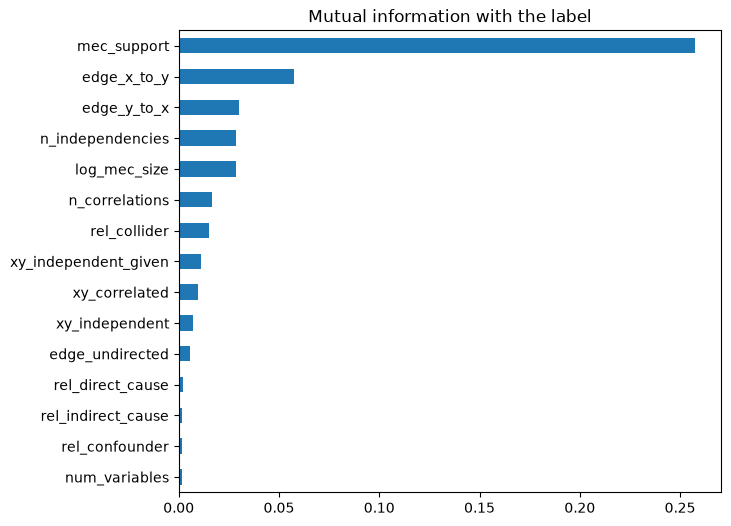

In [12]:
# structured features by mutual information
mi = mutual_info_classif(train[FEATURES], y_train, random_state=42)
pd.Series(mi, index=FEATURES).sort_values().plot(kind="barh", figsize=(7, 6), title="Mutual information with the label")
plt.show()

In [13]:
# does keeping only the top TF-IDF terms help?
select_premise = SelectKBest(chi2, k=50)
X_train_premise_top = select_premise.fit_transform(X_train_premise, y_train)
X_val_premise_top = select_premise.transform(X_val_premise)

select_hypothesis = SelectKBest(chi2, k=30)
X_train_hypothesis_top = select_hypothesis.fit_transform(X_train_hypothesis, y_train)
X_val_hypothesis_top = select_hypothesis.transform(X_val_hypothesis)

X_train_all = np.hstack([X_train_premise, X_train_hypothesis, X_train_structured])
X_val_all = np.hstack([X_val_premise, X_val_hypothesis, X_val_structured])
X_train_top = np.hstack([X_train_premise_top, X_train_hypothesis_top, X_train_structured])
X_val_top = np.hstack([X_val_premise_top, X_val_hypothesis_top, X_val_structured])

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train_all, y_train)
print("all terms     F1:", f1_score(y_val, model.predict(X_val_all)))

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train_top, y_train)
print("top 50 + 30   F1:", f1_score(y_val, model.predict(X_val_top)))

all terms     F1: 0.7986798679867987
top 50 + 30   F1: 0.8157894736842105


Keeping only the top terms changes F1 very little, because the vocabulary is already small (241 terms).
So we keep all terms.

In [14]:
# ─── STEP 7: TF-IDF vs STRUCTURED vs BOTH ─────
X_train_text = np.hstack([X_train_premise, X_train_hypothesis])
X_val_text = np.hstack([X_val_premise, X_val_hypothesis])

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train_text, y_train)
pred_text = model.predict(X_val_text)

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train_structured, y_train)
pred_structured = model.predict(X_val_structured)

model = LogisticRegression(max_iter=2000, class_weight="balanced")
model.fit(X_train_all, y_train)
pred_both = model.predict(X_val_all)

comparison = pd.DataFrame({
    "precision": [precision_score(y_val, pred_text), precision_score(y_val, pred_structured), precision_score(y_val, pred_both)],
    "recall": [recall_score(y_val, pred_text), recall_score(y_val, pred_structured), recall_score(y_val, pred_both)],
    "F1": [f1_score(y_val, pred_text), f1_score(y_val, pred_structured), f1_score(y_val, pred_both)],
}, index=["TF-IDF only", "Structured only", "TF-IDF + structured"])
comparison.round(3)

,precision,recall,F1
TF-IDF only,0.311,0.953,0.469
Structured only,0.634,0.915,0.749
TF-IDF + structured,0.695,0.938,0.799


TF-IDF alone does poorly because word counts can't do causal reasoning. The structured features do much better,
so notebook 04 uses **TF-IDF + structured**.

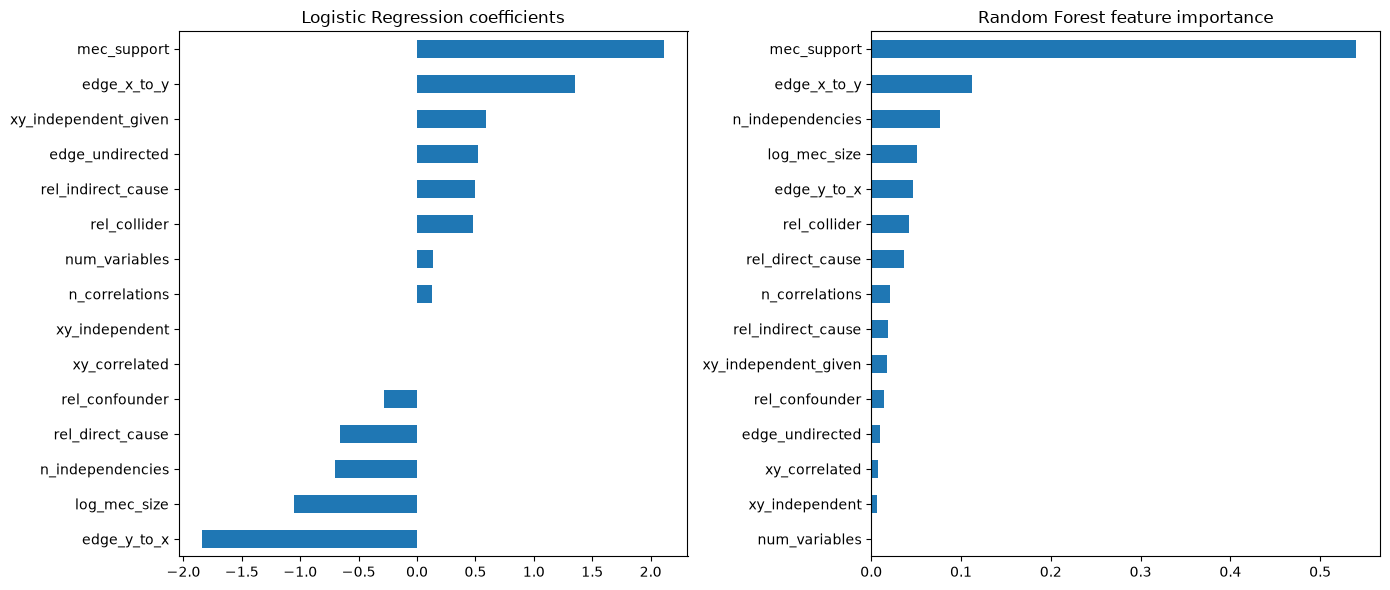

In [15]:
# ─── STEP 8: FEATURE IMPORTANCE ─────
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_train_structured, y_train)
lr_coefs = pd.Series(lr.coef_[0], index=FEATURES).sort_values()

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42)
rf.fit(train[FEATURES], y_train)
rf_importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
lr_coefs.plot(kind="barh", ax=axes[0], title="Logistic Regression coefficients")
rf_importance.plot(kind="barh", ax=axes[1], title="Random Forest feature importance")
plt.tight_layout()
plt.show()

`mec_support` matters most. Logistic Regression also uses the edge direction (`edge_x_to_y` up, `edge_y_to_x` down).

In [16]:
# ─── STEP 9: SAVE AS CSV ─────
columns = ["premise_id", "split", "premise", "hypothesis", "label", "template", "relation", "x", "y"] + FEATURES
data[columns].to_csv("../data/processed/features.csv", index=False)